# Projected Separation Analysis

This notebook analyzes the projected separations of dual nuclei candidates
detected by the YOLOv11x-OBB model.

The notebook includes:

- Catalog inspection
- Descriptive statistics
- Histogram visualization
- Angular separation analysis
- Physical separation analysis

The catalog was generated using the projected separation pipeline
implemented in this repository.

In [24]:
import os
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [25]:
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)

In [26]:
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.grid"] = True

In [27]:
CATALOG_PATH = (
    "../results/finalModel/"
    "projected_separations.csv"
)

df = pd.read_csv(CATALOG_PATH)

logging.info(f"Loaded catalog with {len(df)} rows.")

2026-05-09 18:23:56,945 - INFO - Loaded catalog with 29605 rows.


In [28]:
df.head()

,ObjID,SpecObjID,RA,DEC,Redshift,dist_arcsec,dist_kpc
0,1237650795683512507,299496274514700288,146.95607,-0.342300,0.134680,9.077988,21.678026
1,1237651799621959813,299504520851908608,146.57273,-1.060836,0.060614,9.824729,11.497394
2,1237650795146182725,299516890357721088,146.00779,-0.642272,0.004776,8.773010,0.864970
3,1237650796220121207,299533383032137728,146.34706,0.075416,0.062282,9.420687,11.305631
4,1237650795682791609,299561970334459904,145.36478,-0.342794,0.148621,10.522603,27.299434


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29605 entries, 0 to 29604
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ObjID        29605 non-null  int64  
 1   SpecObjID    29605 non-null  int64  
 2   RA           29605 non-null  float64
 3   DEC          29605 non-null  float64
 4   Redshift     29584 non-null  float64
 5   dist_arcsec  29584 non-null  float64
 6   dist_kpc     29584 non-null  float64
dtypes: float64(5), int64(2)
memory usage: 1.6 MB


In [30]:
df[["dist_arcsec", "dist_kpc"]].describe()

,dist_arcsec,dist_kpc
count,29584.000000,29584.000000
mean,8.713776,17.058116
std,1.861865,9.514261
min,3.971478,-1.003703
25%,7.421395,9.987972
50%,8.559546,15.417201
75%,9.772502,22.655404
max,23.143305,87.375675


In [31]:
def compute_statistics(values, bins=80):

    stats = {}

    stats["N"] = len(values)

    stats["mean"] = values.mean()

    stats["median"] = values.median()

    stats["std"] = values.std()

    stats["min"] = values.min()

    stats["max"] = values.max()

    # Mode
    mode_vals = values.mode()

    stats["mode"] = (
        mode_vals.iloc[0]
        if not mode_vals.empty
        else None
    )

    stats["mode_frequency"] = (
        (values == stats["mode"]).sum()
        if stats["mode"] is not None
        else 0
    )

    # Percentiles
    stats["p25"] = values.quantile(0.25)

    stats["p75"] = values.quantile(0.75)

    # Histogram analysis
    counts, bin_edges = np.histogram(
        values,
        bins=bins
    )

    max_bin_index = np.argmax(counts)

    stats["max_bin_count"] = counts[max_bin_index]

    stats["max_bin_range"] = (
        bin_edges[max_bin_index],
        bin_edges[max_bin_index + 1]
    )

    return stats

In [32]:
def plot_histogram(
    data,
    column_name,
    bins=80,
    save_dir="../docs/figures"
):

    if column_name not in data.columns:

        logging.error(
            f"Column '{column_name}' not found."
        )

        return

    os.makedirs(save_dir, exist_ok=True)

    values = data[column_name].dropna()

    stats = compute_statistics(
        values,
        bins
    )

    plt.figure(figsize=(8, 5))

    plt.hist(
        values,
        bins=bins,
        color="#A37FD3",
        edgecolor="white",
        linewidth=0.8,
        alpha=0.9
    )

    xlabel = (
        "Projected Separation (Arcseconds)"
        if column_name == "dist_arcsec"
        else "Projected Separation (kpc)"
    )

    plt.xlabel(xlabel)

    plt.ylabel("Count")

    # Statistics annotation
    text = (
        f"Mean = {stats['mean']:.3f}\n"
        f"Median = {stats['median']:.3f}\n"
        f"Std = {stats['std']:.3f}\n"
        f"Min = {stats['min']:.3f}\n"
        f"Max = {stats['max']:.3f}"
    )

    plt.text(
        0.97,
        0.97,
        text,
        transform=plt.gca().transAxes,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(
            facecolor="white",
            alpha=0.8
        )
    )

    plt.tight_layout()

    output_path = os.path.join(
        save_dir,
        f"{column_name}_histogram.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    logging.info(
        f"Saved histogram:\n{output_path}"
    )

    return stats

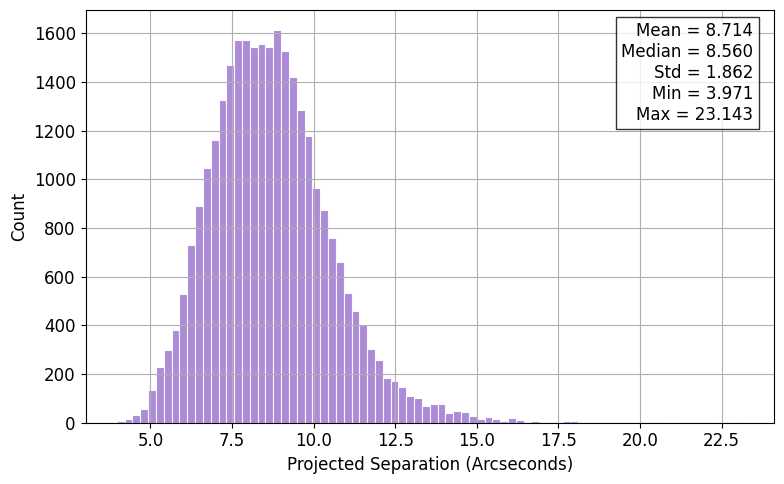

2026-05-09 18:24:18,636 - INFO - Saved histogram:
../docs/figures\dist_arcsec_histogram.png


In [33]:
arcsec_stats = plot_histogram(
    df,
    "dist_arcsec",
    bins=80
)

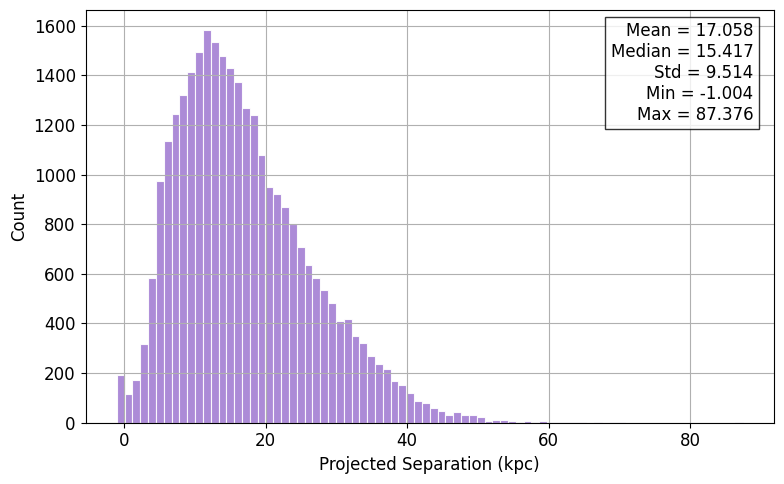

2026-05-09 18:25:49,798 - INFO - Saved histogram:
../docs/figures\dist_kpc_histogram.png


In [36]:
kpc_stats = plot_histogram(
    df,
    "dist_kpc",
    bins=80
)

In [37]:
stats_df = pd.DataFrame(
    [arcsec_stats, kpc_stats],
    index=["dist_arcsec", "dist_kpc"]
)

stats_df

,N,mean,median,std,min,max,mode,mode_frequency,p25,p75,max_bin_count,max_bin_range
dist_arcsec,29584,8.713776,8.559546,1.861865,3.971478,23.143305,3.971478,1,7.421395,9.772502,1615,"(8.76443473054248, 9.004082566460394)"
dist_kpc,29584,17.058116,15.417201,9.514261,-1.003703,87.375675,0.000000,72,9.987972,22.655404,1584,"(11.148461739385517, 12.253203962243868)"


In [ ]:
stats_output_path = (
    "../docs/figures/"
    "statistics_summary.csv"
)

stats_df.to_csv(
    stats_output_path,
    index=True
)

logging.info(
    f"Statistics saved:\n{stats_output_path}"
)

: 

: 

# Summary

This notebook provides exploratory analysis and visualization of
the projected separations derived from YOLOv11x-OBB detections.

The generated plots and statistics can be used for:
- paper figures
- catalog validation
- exploratory data analysis (EDA)
- reproducibility checks